# Carregamento da base de dados

# === Compatibilidad SDK SageMaker v3 ===
import os
os.environ['SAGEMAKER_SUPPRESS_V2_WARNING'] = '1'

import sagemaker
from sagemaker.session import Session, get_execution_role
from importlib.metadata import version

# El __init__.py de v3 ya no re-exporta estos símbolos, pero
# módulos internos del propio SDK todavía los buscan ahí.
sagemaker.Session = Session
sagemaker.get_execution_role = get_execution_role

print("SDK SageMaker:", version("sagemaker"))

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np

In [2]:
base_casas = pd.read_csv('house_prices.csv')
base_casas

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [3]:
base_casas.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [4]:
base_casas.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Búsqueda de Missing Values

In [5]:
base_casas.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

# Visualização dos dados

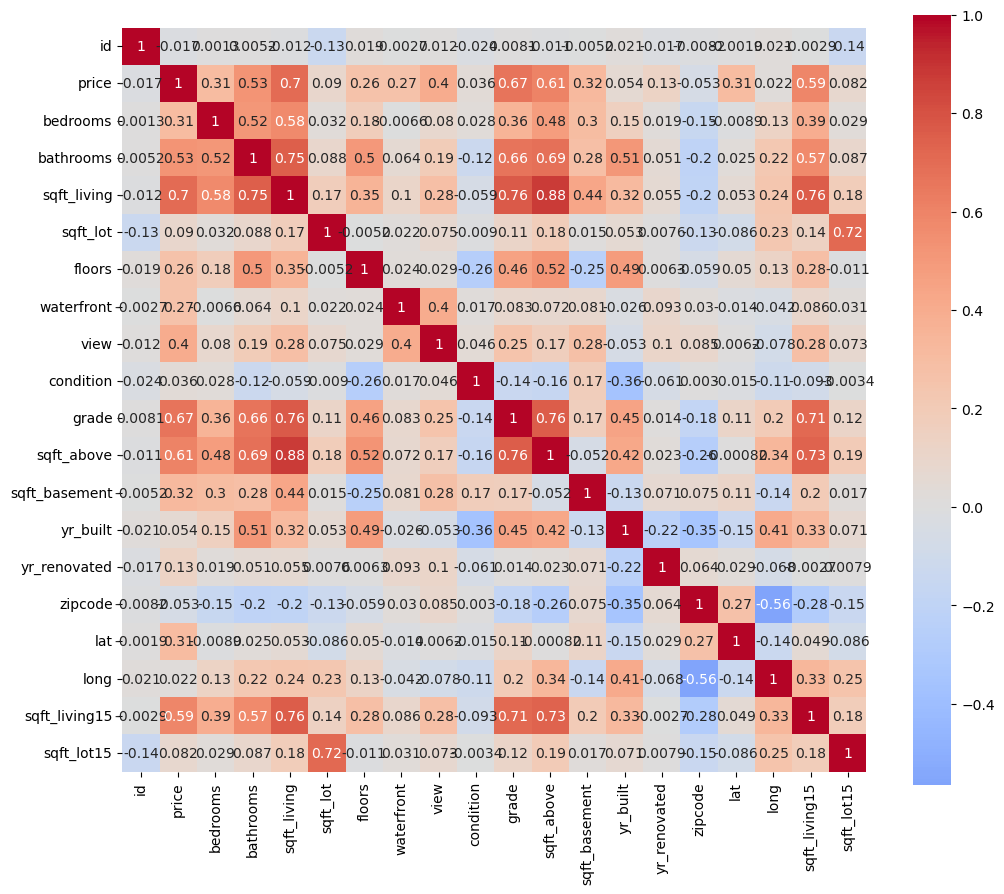

In [6]:
numeric_cols = base_casas.select_dtypes(include=['int64', 'float64']).columns
correlacion = base_casas[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlacion, cmap='coolwarm', center=0, square=True, annot=True)
plt.show()

# Pré-processamento dos dados

In [7]:
base_casas.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [8]:
#Solo cogemos las columnas desde "bedrooms" hasta la columna "long"
X = base_casas.iloc[:, 3:19].values
X

array([[ 3.00000e+00,  1.00000e+00,  1.18000e+03, ...,  9.81780e+04,
         4.75112e+01, -1.22257e+02],
       [ 3.00000e+00,  2.25000e+00,  2.57000e+03, ...,  9.81250e+04,
         4.77210e+01, -1.22319e+02],
       [ 2.00000e+00,  1.00000e+00,  7.70000e+02, ...,  9.80280e+04,
         4.77379e+01, -1.22233e+02],
       ...,
       [ 2.00000e+00,  7.50000e-01,  1.02000e+03, ...,  9.81440e+04,
         4.75944e+01, -1.22299e+02],
       [ 3.00000e+00,  2.50000e+00,  1.60000e+03, ...,  9.80270e+04,
         4.75345e+01, -1.22069e+02],
       [ 2.00000e+00,  7.50000e-01,  1.02000e+03, ...,  9.81440e+04,
         4.75941e+01, -1.22299e+02]])

In [9]:
X.shape

(21613, 16)

In [10]:
#Vemos los datos de la primera casa (fila)
X[0]

array([ 3.00000e+00,  1.00000e+00,  1.18000e+03,  5.65000e+03,
        1.00000e+00,  0.00000e+00,  0.00000e+00,  3.00000e+00,
        7.00000e+00,  1.18000e+03,  0.00000e+00,  1.95500e+03,
        0.00000e+00,  9.81780e+04,  4.75112e+01, -1.22257e+02])

### Observamos los precios de las casas

In [11]:
y = base_casas.iloc[:, 2].values
y

array([221900., 538000., 180000., ..., 402101., 400000., 325000.])

In [12]:
y.shape

(21613,)

### Necesitamos convertir X y Y a Vector

In [13]:
X = np.array(X).astype('float32')
y = np.array(y).astype('float32')

### Dividimos el dataset en entrenamiento y prueba

In [14]:
from sklearn.model_selection import train_test_split

X_entrenamiento, X_test, y_entrenamiento, y_test = train_test_split(X, y, test_size = 0.3, random_state=0)

In [15]:
X_entrenamiento.shape, X_test.shape

((15129, 16), (6484, 16))

In [16]:
y_entrenamiento.shape, y_test.shape

((15129,), (6484,))

In [17]:
X_entrenamiento.min(), X_entrenamiento.max()

(-122.514, 1651359.0)

# Configuraciones SageMaker

### Importación de librerías

In [18]:
import sagemaker
import boto3
from sagemaker.session import Session

sess = Session()

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


/opt/conda/lib/python3.12/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


### Configuración del Bucket y rutas

In [19]:
session = Session()   # ya la importaste arriba
bucket = 'aws-sagemaker-datapath-ml-regresion-linear-learner-k'
subcarpeta_modelo = 'modelos/house-prices/linear-learner'
subcarpeta_dataset = 'datasets/house-prices'

### Ros de ejecución (IAM Role)
#### Con `sagemaker.get_execution_role()` obtenemos los **permisos del usuario** que permiten a SageMaker acceder a S3, entrenar modelos y desplegar endpoints.

In [20]:
from sagemaker.session import get_execution_role

role = get_execution_role()
print(role)

arn:aws:iam::123456789012:role/service-role/AmazonSageMaker-ExecutionRole-20260818T191520


### Conversión de datos a formato RecordIO-Protobuf
#### SageMaker Linear Learner requiere que los datos estén en un formato binario específico llamado **RecordIO-Protobuf** (es mucho más eficiente que CSV para entrenar modelos grandes).

In [21]:
import io
import sagemaker.amazon.common as smac # sagemaker commom library

buffer = io.BytesIO()
smac.write_numpy_to_dense_tensor(buffer, X_entrenamiento, y_entrenamiento)
buffer.seek(0)

0

### Subida de datos a S3
#### **key** → Nombre del archivo: `houses-train-data`
#### Se sube a la ruta: `datasets/house-prices/train/houses-train-data`.

In [22]:
import os
key = 'houses-train-data' #Base de datos de Entrenamiento
boto3.resource('s3').Bucket(bucket).Object(os.path.join(subcarpeta_dataset, 'train', key)).upload_fileobj(buffer)

In [23]:
os.path.join(subcarpeta_dataset, 'train', key)

'datasets/house-prices/train/houses-train-data'

### Definición de rutas finales
**s3_train_data** → Ruta completa de los datos de entrenamiento en S3.

**output_location** → Ruta donde SageMaker guardará el modelo entrenado cuando termine el proceso.

In [24]:
#Verificamos que esté en S3
s3_train_data = 's3://{}/{}/train/{}'.format(bucket, subcarpeta_dataset, key)
print('Localizacion de la base de entrenamiento: {}'.format(s3_train_data))

Localizacion de la base de entrenamiento: s3://aws-sagemaker-datapath-ml-regresion-linear-learner-k/datasets/house-prices/train/houses-train-data


In [25]:
output_location = 's3://{}/{}/output'.format(bucket, subcarpeta_modelo)
print('Modelo final será guardado en: {}'.format(output_location))

Modelo final será guardado en: s3://aws-sagemaker-datapath-ml-regresion-linear-learner-k/modelos/house-prices/linear-learner/output


# Criação e treinamento do Linear Learner

In [26]:
boto3.Session().region_name

'us-east-2'

In [27]:
from sagemaker.image_uris import retrieve
container = retrieve(framework='linear-learner', region=boto3.Session().region_name)

In [37]:
# https://aws.amazon.com/ec2/instance-types/
# https://docs.aws.amazon.com/pt_br/AWSEC2/latest/UserGuide/instance-types.html
# https://docs.aws.amazon.com/sagemaker/latest/dg/notebooks-available-instance-types.html
# https://sagemaker.readthedocs.io/en/stable/api/training/estimators.html
# https://aws.amazon.com/pt/about-aws/whats-new/2019/08/amazon-sagemaker-launches-managed-spot-training-saving-machine-learning-training-costs/
from sagemaker.estimator import Estimator

linear = Estimator(
    image_uri=container,
    role=role,
    instance_count=1,
    instance_type='ml.m4.xlarge',
    output_path=output_location,
    sagemaker_session=session,
    use_spot_instances=True,
    max_run=3600,
    max_wait=3600
)

In [38]:
# https://docs.aws.amazon.com/sagemaker/latest/dg/ll_hyperparameters.html
linear.set_hyperparameters(feature_dim = 16, #Tenemos 16 columnas
                           predictor_type = 'regressor',
                           num_models = 16) #Entrenaremos 16 modelos y nos quedamos con el mejor

In [39]:
linear.fit({'train': s3_train_data})

INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker:Creating training-job with name: linear-learner-2026-08-20-22-14-01-671
ERROR:sagemaker:Please check the troubleshooting guide for common errors: https://docs.aws.amazon.com/sagemaker/latest/dg/sagemaker-python-sdk-troubleshooting.html#sagemaker-python-sdk-troubleshooting-create-training-job


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:1                                                                                    │
│                                                                                                  │
│ ❱ 1 linear.fit({'train': s3_train_data})                                                         │
│   2                                                                                              │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/sagemaker/telemetry/telemetry_logging.py:171 in wrapper  │
│                                                                                                  │
│   168 │   │   │   │   │   caught_ex = e                                                          │
│   169 │   │   │   │   finally:                                                                   │
│   170 │   │   │   │   │   if caught_ex:                                                          │
│ ❱ 171 │   │   │   │   │   │   raise caught_ex                                                    │
│   172 │   │   │   │   │   return response  # pylint: disable=W0150                               │
│   173 │   │   │   else:                                                                          │
│   174 │   │   │   │   logger.debug(                                                              │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/sagemaker/telemetry/telemetry_logging.py:142 in wrapper  │
│                                                                                                  │
│   139 │   │   │   │   start_timer = perf_counter()                                               │
│   140 │   │   │   │   try:                                                                       │
│   141 │   │   │   │   │   # Call the original function                                           │
│ ❱ 142 │   │   │   │   │   response = func(*args, **kwargs)                                       │
│   143 │   │   │   │   │   stop_timer = perf_counter()                                            │
│   144 │   │   │   │   │   elapsed = stop_timer - start_timer                                     │
│   145 │   │   │   │   │   extra += f"&x-latency={round(elapsed, 2)}"                             │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/sagemaker/workflow/pipeline_context.py:346 in wrapper    │
│                                                                                                  │
│   343 │   │   │                                                                                  │
│   344 │   │   │   return _StepArguments(retrieve_caller_name(self_instance), run_func, *args,    │
│   345 │   │                                                                                      │
│ ❱ 346 │   │   return run_func(*args, **kwargs)                                                   │
│   347 │                                                                                          │
│   348 │   return wrapper                                                                         │
│   349                                                                                            │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/sagemaker/estimator.py:1438 in fit                       │
│                                                                                                  │
│   1435 │   │   self._prepare_for_training(job_name=job_name)                                     │
│   1436 │   │                                               

# Deploy, previsões e avaliação

In [ ]:
# https://aws.amazon.com/pt/ec2/instance-types/inf1/
linear_regressor = linear.deploy(initial_instance_count=1, instance_type='ml.m5.xlarge')